# ¿Se conservan las asociaciones en otra partición de series?

**Pregunta:** ¿Qué asociaciones diagnósticas sobreviven al separar descubrimiento y confirmación, y reduce el error un selector basado en características? Examinamos el estudio completo M4 Daily bajo su protocolo fijo. La lección distingue tres evidencias: pruebas de asociación, una regla aprendida de selección y un oráculo que conoce los resultados futuros. Una respuesta fuerte en una de ellas no resuelve automáticamente las otras; un selector desfavorable debe permanecer visible aunque varias pruebas rechacen sus hipótesis nulas.

## Objetivos

Siga las características de prefijos entre particiones separadas, repita la corrección de pruebas dependientes y vuelva a entrenar el selector. Distinga una asociación del error reservado de una regla de selección utilizable.

## Preparación

Instale el entorno fijado y lea el artefacto compacto del corpus ejecutado. Contiene características por serie, medidas de modelos, índices de origen e identidades de partición, no todas las observaciones descargadas. La auditoría externa del productor repuntuó independientemente cada método y origen antes de exportar estas filas. Aquí podemos repetir el análisis estadístico y entrenar el selector con la tabla admitida, sin descargar el corpus bruto ni presentar predicciones almacenadas como ajustes nuevos.

pip install numpy==2.4.6
pip install scipy==1.15.3
pip install matplotlib==3.10.8
pip install statsforecast==2.0.3
pip install lightgbm==4.6.0
pip install mlforecast==1.0.31
pip install nbformat==5.11.1
pip install nbclient==0.11.0
pip install ipykernel==7.4.0
pip install stumpy==1.14.1
pip install antropy==0.2.2
pip install nolds==0.6.3
pip install pycatch22==0.4.5
pip install scikit-learn==1.9.1
pip install preqts==0.3.0


In [1]:
# Configure a portable session and suppress only the known repeated-shape control warning.
from pathlib import Path
import sys
import json
import warnings
import numpy as np
import matplotlib.pyplot as plt
root = next(p for p in Path.cwd().parents if (p / "VERSION").is_file())
sys.path.insert(0, str(root / "data-pipeline"))
from chronoscopelab.analysis.sequence import matrix_profile, sequence_report
from chronoscopelab.analysis.sequence import multiscale_entropy, time_reversal
from chronoscopelab.analysis.atlas import prefix_features, associations, by_adjust
plt.rcParams.update({"figure.figsize": (8, 3), "figure.dpi": 95, "font.size": 10})
plt.rcParams["svg.hashsalt"] = "chronoscope-sequence-lessons"
warnings.filterwarnings("ignore", message="A large number of values in.*", category=UserWarning)
import importlib.metadata
packages = ("numpy", "scipy", "matplotlib", "stumpy", "antropy", "nolds", "pycatch22", "scikit-learn",
            "statsforecast", "lightgbm", "mlforecast", "nbformat", "nbclient", "ipykernel")
for package in packages:
    print(package, importlib.metadata.version(package))


numpy 2.4.6
scipy 1.15.3
matplotlib 3.10.8
stumpy 1.14.1
antropy 0.2.2
nolds 0.6.3
pycatch22 0.4.5
scikit-learn 1.9.1
statsforecast 2.0.3
lightgbm 4.6.0
mlforecast 1.0.31
nbformat 5.11.1
nbclient 0.11.0
ipykernel 7.4.0


## Datos

El artefacto admitido conserva la identidad y las observaciones utilizadas a continuación.


In [2]:
# Read the complete admitted feature and error table with its series partitions.
analysis = json.loads((root / "data/derived/BRKV_level_shift/analysis.json").read_text(encoding="utf-8"))
values = np.array(analysis["sequence"]["values"], dtype=float)
print("Original observations:", len(values))
study = json.loads((root / "data/derived/forecastability.json").read_text(encoding="utf-8"))
discovery = [r for r in study["series"] if r["partition"] == "discovery"]
confirmation = [r for r in study["series"] if r["partition"] == "confirmation"]
print("Source series:", study["source_n"])
print("Admitted series:", study["included_n"])
print("Origins per series:", study["protocol"]["origins"])
print("Discovery/confirmation:", len(discovery), len(confirmation))


Original observations: 300
Source series: 4227
Admitted series: 4226
Origins per series: 3
Discovery/confirmation: 2946 1280


## Método

La fuente contiene 4.227 series diarias. Cada secuencia admitida aporta tres bloques separados de catorce pasos; cada ajuste utiliza hasta 1.024 observaciones contiguas anteriores. Las características se calculan una sola vez en el primer origen, de modo que ninguno de esos bloques futuros entra en su cálculo. La estacionalidad diaria del pronóstico es uno. Un diagnóstico semanal separado no cambia ese ajuste. Los duplicados exactos conservan una identidad para inferencia y las exclusiones mantienen sus razones.


In [3]:
# Extract features before all three held-out target blocks in the worked case.
features = prefix_features(values[:-42])
print("Features available before the three final blocks:", len(features))
print("Earliest prefix observations:", features["history_length"])


Features available before the three final blocks: 40
Earliest prefix observations: 258.0


La llamada de prefijo muestra el mismo límite informativo sobre un caso comprometido cuyas observaciones originales están disponibles. Sus cuarenta características combinan resúmenes estadísticos con diagnósticos de orden. El ejemplo no reemplaza una fila M4 ni pretende reconstruir el corpus bruto desde la salida compacta. En el estudio, cada vector M4 procede del primer prefijo de su propia serie y su identidad queda vinculada al archivo externo de origen.

El objetivo es log(1 + mejor MASE medio dentro de los ocho métodos fijados). El error de cada método se promedia entre los tres orígenes antes de escoger el mínimo por serie. Es un objetivo optimista porque los resultados futuros identifican al ganador. Describe el error alcanzable entre esas configuraciones, no una predictibilidad inherente. Una característica también puede relacionarse con la construcción del denominador MASE sin revelar un mecanismo físico útil para pronosticar.


In [4]:
# Repeat all preregistered feature tests in each disjoint series partition.
discovery_tests = associations(discovery)
confirmation_tests = associations(confirmation)
print("Hypotheses per partition:", len(discovery_tests))
print("Rejected in discovery:", sum(r["rejected"] for r in discovery_tests))
print("Rejected in confirmation:", sum(r["rejected"] for r in confirmation_tests))


Hypotheses per partition: 40
Rejected in discovery: 25
Rejected in confirmation: 21


Las series de descubrimiento y confirmación son distintas por identidad exacta de secuencia. Su asignación es determinista e independiente de las etiquetas de error. Contrastamos todas las características registradas en cada partición y conservamos tamaños de muestra, efectos Kendall y probabilidades. La unidad es una serie; cada origen no se trata como réplica independiente. Promediar orígenes evita ese riesgo inmediato de pseudorreplicación, pero no demuestra independencia entre sectores u orígenes subyacentes de diferentes series.

## Comparación


In [5]:
# Check the chosen confirmation association against SciPy Kendall tau.
from scipy import stats
chosen = "linear_trend_r"
pairs = [(r["features"][chosen], np.log1p(min(r["mase"].values())))
         for r in confirmation if r["features"][chosen] is not None]
x, y = zip(*pairs)
tau, probability = stats.kendalltau(x, y)
print("Reference feature:", chosen)
print("Kendall tau:", round(float(tau), 6))
print("Reference probability:", float(probability))


Reference feature: linear_trend_r
Kendall tau: 0.147041
Reference probability: 3.2664554785751826e-15


El cálculo directo de SciPy comprueba una característica escogida explícitamente frente a la implementación Kendall de referencia. Usa filas de confirmación con valores disponibles y el mismo objetivo transformado. El coeficiente mide asociación monótona, no una respuesta causal ajustada. La biblioteca trata los empates. Una probabilidad pequeña debe leerse dentro de toda la familia, en vez de informarse aisladamente porque una característica haya resultado interesante.


In [6]:
# Compare dependent-test BY adjustment with the reference implementation.
probabilities = [r["p"] for r in confirmation_tests]
corrected = by_adjust(probabilities)
library = stats.false_discovery_control(probabilities, method="by")
print("Maximum BY reference difference:", f"{np.max(np.abs(corrected-library)):.8f}")
print("Confirmation threshold:", study["protocol"]["q"])


Maximum BY reference difference: 0.00000000
Confirmation threshold: 0.05


La corrección BY emplea la cantidad de pruebas y su factor armónico para tratar la dependencia entre hipótesis de características. Comparamos el resultado del producto con la referencia sobre toda la familia de confirmación. Confirmar exige rechazo corregido en ambas particiones y la misma dirección. Escoger primero únicamente probabilidades pequeñas y después corregir definiría un procedimiento diferente y engañoso. Ninguna corrección elimina dependencias no medidas entre fuentes relacionadas del benchmark.


In [7]:
# Verify a prefix-only profile without admitting future observations.
same_prefix = values[:-42]
product_profile = matrix_profile(same_prefix, window=24)
import stumpy
library_profile = stumpy.stump(same_prefix, m=24)
print("Prefix-only profile difference:",
      f"{np.max(np.abs(np.asarray(product_profile['profile'])-library_profile.P_)):.8f}")


Prefix-only profile difference: 0.00000000


La comparación exacta del perfil usa un prefijo que termina antes de los tres bloques finales del caso trabajado. Comprueba que el adaptador puede operar dentro del límite temporal sin requerir la secuencia futura completa. El perfil retrospectivo de la app y este cálculo de prefijo cumplen, por tanto, funciones diferentes. Sus coordenadas conservan las unidades originales, pero los vecinos elegibles y las distancias pueden cambiar porque las observaciones disponibles son distintas.


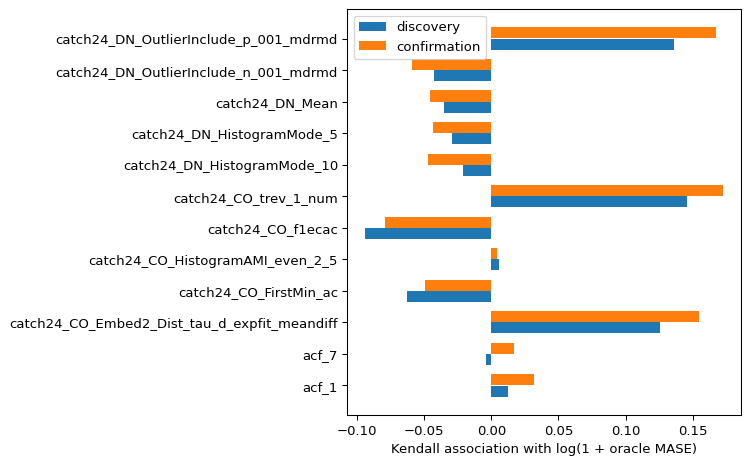

In [8]:
# Show the first twelve features in schema order rather than significance order.
chosen_tests = study["summary"]["associations"][:12]
fig, ax = plt.subplots(figsize=(8, 5))
locations = np.arange(len(chosen_tests))
ax.barh(locations-.18, [r["discovery"]["tau"] for r in chosen_tests], height=.35, label="discovery")
ax.barh(locations+.18, [r["confirmation"]["tau"] for r in chosen_tests], height=.35, label="confirmation")
ax.set_yticks(locations, [r["feature"] for r in chosen_tests])
ax.set(xlabel="Kendall association with log(1 + oracle MASE)")
ax.legend()
fig.tight_layout()
plt.show()


La figura presenta las primeras doce características en el orden fijo del esquema, no una selección por probabilidades mínimas. Las cuarenta pruebas permanecen en el artefacto y en la tabla corregida de la app. Compare magnitud y dirección entre particiones antes de leer el indicador de rechazo. Coeficientes parecidos aportan evidencia condicional; cambios de signo o efectos que desaparecen deben conservarse como hallazgos y no retirarse de la presentación.


In [9]:
# Train the fixed selector again using discovery rows and discovery-only imputation.
from chronoscopelab.analysis.atlas import study_summary
reproduced, trained_selector = study_summary(study["series"])
differences = [abs(reproduced["selection_mean_mase"][n]-study["summary"]["selection_mean_mase"][n])
               for n in reproduced["selection_mean_mase"]]
print("Maximum reproduced selection-score difference:", f"{max(differences):.8f}")
assert len(set(r["sequence_sha256"] for r in study["series"])) == study["included_n"]
assert not set(r["id"] for r in discovery) & set(r["id"] for r in confirmation)
assert np.allclose(corrected, library)
print("Duplicate, partition and corrected-probability checks passed")


Maximum reproduced selection-score difference: 0.00000000
Duplicate, partition and corrected-probability checks passed


El selector se vuelve a entrenar con las filas compactas de descubrimiento. Usa el bosque fijo y medianas calculadas solo allí para valores ausentes. Las etiquetas de confirmación no eligen hiperparámetros, umbrales ni el método constante. Comparamos las medidas reproducidas con las exportadas; la siguiente figura procede de un entrenamiento ejecutado sobre la tabla pública. Repetir esta capa de selección es diferente de reajustar los ocho métodos de pronóstico sobre todo el corpus externo.

## Resultados

**Respuesta:** El selector obtiene MASE medio 3.3501 frente a 3.2570 de la constante de descubrimiento. Los conteos admitidos, decisiones corregidas y errores de selección confirmatoria responden la pregunta fija del corpus. Reproducir la puntuación verifica el cálculo de la tabla; no convierte el oráculo retrospectivo en una política ni establece superioridad poblacional.


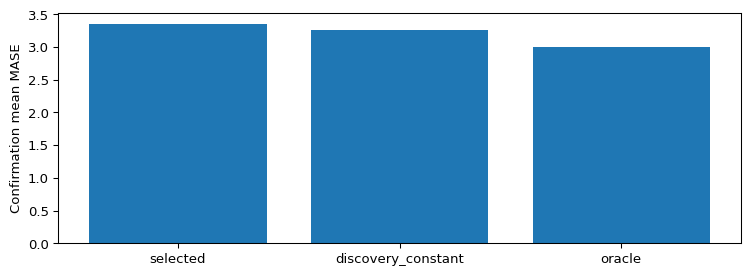

selected 3.3501
discovery_constant 3.257
oracle 3.0005


In [10]:
# Plot confirmation scores from the reproduced selection calculation.
scores = reproduced["selection_mean_mase"]
fig, ax = plt.subplots()
ax.bar(list(scores), list(scores.values()))
ax.set(ylabel="Confirmation mean MASE")
fig.tight_layout()
plt.show()
for name, score in scores.items():
    print(name, round(score, 4))


La barra del oráculo usa medidas futuras para elegir un ganador distinto en cada serie de confirmación. Es una referencia inferior dentro del conjunto, no una regla desplegable. El método constante se eligió solo en descubrimiento y el bosque decide usando características de prefijos disponibles. Lea ambas reglas sobre las mismas filas y unidades. Un error bajo del oráculo puede coexistir con un selector desfavorable porque las características no identifican fiablemente a los ganadores individuales.

Respuesta: el selector reproducido tiene MASE medio de confirmación 3.3501, frente a 3.2570 del método constante elegido en descubrimiento. 21 características cumplen la regla declarada de confirmación en dos particiones. Son conclusiones diferentes: una asociación no garantiza mejorar la selección discreta de métodos, y una diferencia observada tampoco establece superioridad poblacional. La fuente tiene 4.227 series y se usan tres orígenes; la muestra estadística corresponde a las series distintas admitidas.

### Limitaciones

El corpus representa una frecuencia de benchmark con identidades de fuente anonimizadas. La deduplicación exacta no reconoce todos los sectores relacionados ni factores latentes compartidos. El conjunto excluye modelos profundos y preentrenados y no puede ordenarlos por implicación. El contexto limitado, los ajustes fijos y el oráculo de error escalado acotan el significado del objetivo. Ningún resultado modifica las características o parámetros del bosque. El otro experimento de veintidós variantes permanece disponible con sus propias identidades y procedencia.

### Sensibilidad al resumen de rendimiento

Sea $\overline E_{i,k}$ el MASE medio sobre los tres orígenes reservados de la serie $i$ con el método $k$. La asociación por rangos usa una transformación del oráculo dentro del conjunto de métodos.

$$
A_i=\log(1+\min_k \overline E_{i,k}).
$$

Para las series de confirmación, sea $k_i$ la elección del bosque a partir de las características del prefijo y $k_0$ el método elegido por MASE medio en descubrimiento. La comparación entre estas dos políticas aplicables utiliza

$$
\Delta_i=\overline E_{i,k_i}-\overline E_{i,k_0},
\qquad \overline\Delta=\frac{1}{N}\sum_{i=1}^{N}\Delta_i.
$$

El oráculo toma el mínimo cuando ya se conocen todos los resultados. El selector y la regla constante eligen antes de usar los resultados de confirmación. Una asociación fuerte con $A_i$ puede aparecer porque varios métodos obtienen poco error en la misma serie. No indica al bosque cuál método concreto gana. La figura muestra la distribución acumulada empírica de las diferencias emparejadas en confirmación. Cada serie aporta un valor, independientemente de la longitud de su historia.


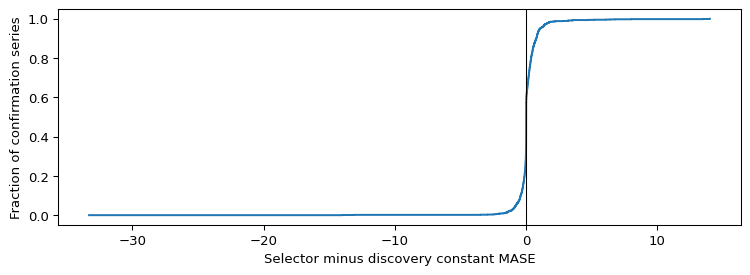

Lower, tied, higher: 599 24 657
Mean paired difference: 0.093148


In [11]:
# Inspect confirmation-series differences behind the aggregate selector score.
constant_name = reproduced["constant_method"]
paired = np.sort([row["mase"][row["selected_method"]] - row["mase"][constant_name]
                  for row in confirmation])
fig, ax = plt.subplots()
ax.step(paired, np.arange(1, len(paired) + 1) / len(paired), where="post")
ax.axvline(0, color="black", linewidth=0.8)
ax.set(xlabel="Selector minus discovery constant MASE", ylabel="Fraction of confirmation series")
fig.tight_layout()
plt.show()
print("Lower, tied, higher:", int(sum(paired < 0)), int(sum(paired == 0)), int(sum(paired > 0)))
print("Mean paired difference:", round(float(paired.mean()), 6))


Para leer la distribución, ubique el cero. A la izquierda se favorece al selector y a la derecha al método constante de descubrimiento. Un salto en cero puede deberse a que ambas reglas eligen el mismo método o a que sus puntajes empatan. Una cola de diferencias grandes puede mover la media, así que compárela con los conteos por dirección. Estas observaciones reutilizan la confirmación para describir el resultado fijo. No use las colas para retirar series difíciles, elegir otra característica o reajustar el bosque en confirmación.

### Adapta el diseño a tus propios datos

Identifique grupos que comparten un proceso antes de crear la partición. Varios canales de una instalación, por ejemplo, pueden ser secuencias distintas que revelan un régimen común. Mantenga los canales relacionados del mismo lado de la separación. Declare la regla para excluir secuencias cortas y escalas nulas y registre cada identidad excluida. Defina horizonte y corte de características de forma consistente, con información conocida antes de todos los objetivos que se puntúan.

Ajuste la imputación, la elección de referencia y los parámetros del selector con descubrimiento. Para confirmar, use el flujo ajustado fijo y evalúe las dos reglas sobre las mismas series y orígenes. Compare diferencias emparejadas y conteos como en la figura. Si pocos errores extremos dominan el resultado, consérvelos y documente su procedencia. Use otro grupo intacto para evaluar una política revisada. Así puede estudiar la selección de métodos para un conjunto, frecuencia y población especificados, sin atribuir el resultado a un límite intrínseco de predictibilidad.

## Resumen

La partición de confirmación evalúa reglas e hipótesis fijadas previamente. Conserve familia corregida completa, exclusiones y resultados negativos junto a cualquier coeficiente favorable.

### Reproducir


Ejecute las celdas y compare correcciones de referencia, medidas reproducidas del selector y comprobaciones de partición. Reproducir los pronósticos completos requiere además el TSF licenciado y el evaluador externo; el repositorio documenta su suma de verificación, caché y puntuación independiente de trayectorias. Este cuaderno reproduce la capa inferencial y de selección y declara expresamente ese límite.

## Referencias

Monash M4 Daily, DOI 10.5281/zenodo.4656548. La documentación tsfresh explica la corrección BY para pruebas dependientes. Hyndman y Koehler, DOI 10.1016/j.ijforecast.2006.03.001, examinan el error escalado. STUMPY documenta el perfil exacto de prefijo usado como comparación numérica.

[Dependent-test feature filtering](https://tsfresh.readthedocs.io/en/v0.21.0/text/feature_filtering.html); [Matrix Profile reference](https://doi.org/10.1109/ICDM.2016.0179).
